In [2]:
import sys
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages

PROJECT_ROOT = Path.cwd()
# print(PROJECT_ROOT)
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_ingestion import DataIngestion

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 100})
REPORTS_DIR = PROJECT_ROOT / "artifacts" / "diagnostic_plots"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")




Project root: c:\Users\Priya Bhaskar\OneDrive\Documents\p4_fraud_detection\insurance_fraud_detection


In [3]:
df = DataIngestion().load_data()
print(df.shape)
df.head()

(10000, 20)


,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0


In [4]:
df["Claim_ID"].shape

(10000,)

In [5]:
type(df)

pandas.DataFrame

In [6]:
type(df["Claim_ID"])

pandas.Series

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Provider_ID                            10000 non-null  str    
 1   Claim_ID                               10000 non-null  str    
 2   Patient_Age                            10000 non-null  int64  
 3   Patient_Gender                         10000 non-null  str    
 4   Diagnosis_Code                         10000 non-null  str    
 5   Procedure_Code                         10000 non-null  int64  
 6   Claim_Amount                           10000 non-null  float64
 7   Approved_Amount                        10000 non-null  float64
 8   Insurance_Type                         10000 non-null  str    
 9   Claim_Submission_Date                  10000 non-null  str    
 10  Days_Between_Service_and_Claim         10000 non-null  int64  
 11  Number_of_Clai

In [9]:
df.isnull().sum()

Provider_ID                                0
Claim_ID                                   0
Patient_Age                                0
Patient_Gender                             0
Diagnosis_Code                             0
Procedure_Code                             0
Claim_Amount                               0
Approved_Amount                            0
Insurance_Type                             0
Claim_Submission_Date                      0
Days_Between_Service_and_Claim             0
Number_of_Claims_Per_Provider_Monthly      0
Provider_Specialty                         0
Patient_State                              0
Claim_Status                               0
Is_Fraud                                   0
Length_of_Stay                             0
Visit_Type                                 0
Chronic_Condition_Flag                     0
Prior_Visits_12m                         350
dtype: int64

In [11]:
missing = pd.DataFrame({"count": df.isna().sum(), "percent": (df.isnull().sum()/len(df) * 100)})
display(missing.sort_values("percent", ascending=False))


,count,percent
Prior_Visits_12m,350,3.5
Provider_ID,0,0.0
Patient_Age,0,0.0
Claim_ID,0,0.0
Patient_Gender,0,0.0
Diagnosis_Code,0,0.0
Claim_Amount,0,0.0
Procedure_Code,0,0.0
Insurance_Type,0,0.0
Claim_Submission_Date,0,0.0


In [12]:
print(f"Duplicate values: {df.duplicated().sum()}")

Duplicate values: 0


<function matplotlib.pyplot.show(close=None, block=None)>

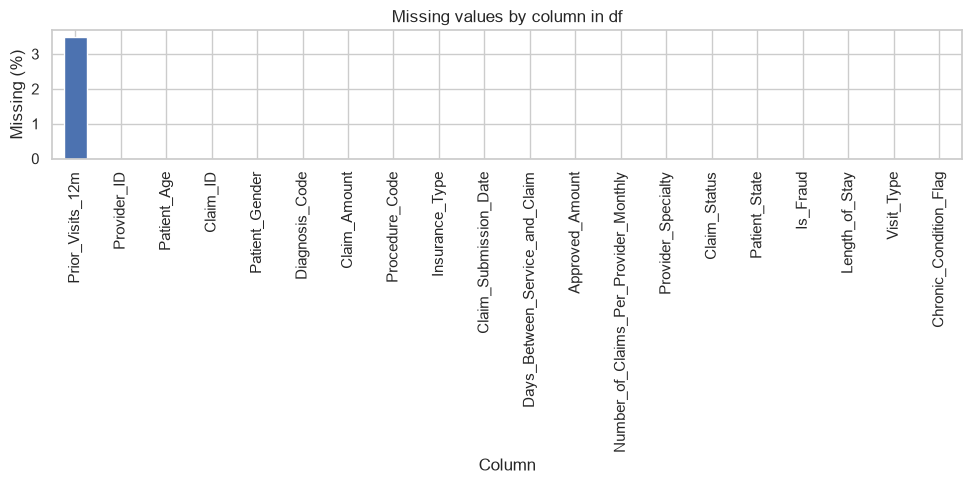

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
missing.sort_values("percent", ascending=False)["percent"].plot(kind="bar", ax=ax)
ax.set(title="Missing values by column in df", ylabel="Missing (%)", xlabel="Column")
fig.tight_layout()
plt.show


In [17]:
# missing.sort_values("percent", ascending=False)["percent"]

In [19]:
df["Is_Fraud"].value_counts()

Is_Fraud
0    9171
1     829
Name: count, dtype: int64

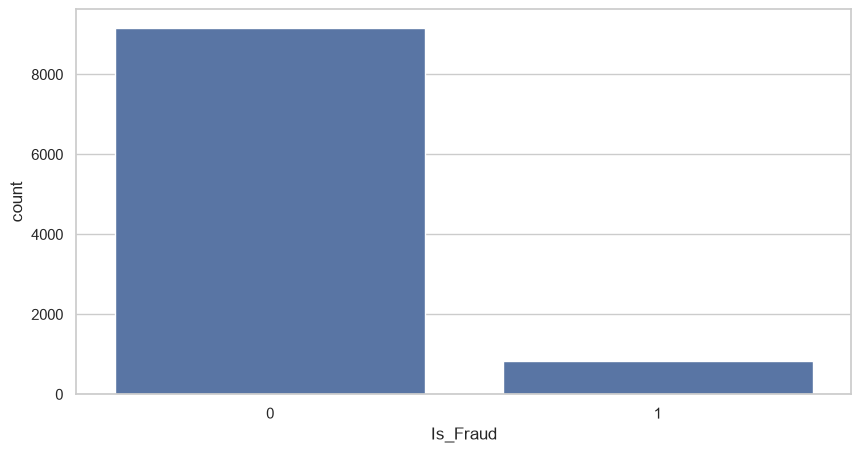

In [20]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Is_Fraud")
plt.show()

In [31]:
exclude_predictive_cols = ["Approved_Amount", "Claim_Status", "Provider_ID", "Claim_ID"]

numerical_cols = df.select_dtypes(include=["int", "float"]).columns.tolist()
numerical_cols = [col for col in numerical_cols if col not in exclude_predictive_cols]
numerical_cols

['Patient_Age',
 'Procedure_Code',
 'Claim_Amount',
 'Days_Between_Service_and_Claim',
 'Number_of_Claims_Per_Provider_Monthly',
 'Is_Fraud',
 'Length_of_Stay',
 'Chronic_Condition_Flag',
 'Prior_Visits_12m']

In [32]:
categorical_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()

In [33]:
type(categorical_cols)

list

In [34]:
categorical_cols = [col for col in categorical_cols if col not in exclude_predictive_cols]

In [35]:
categorical_cols

['Patient_Gender',
 'Diagnosis_Code',
 'Insurance_Type',
 'Claim_Submission_Date',
 'Provider_Specialty',
 'Patient_State',
 'Visit_Type']

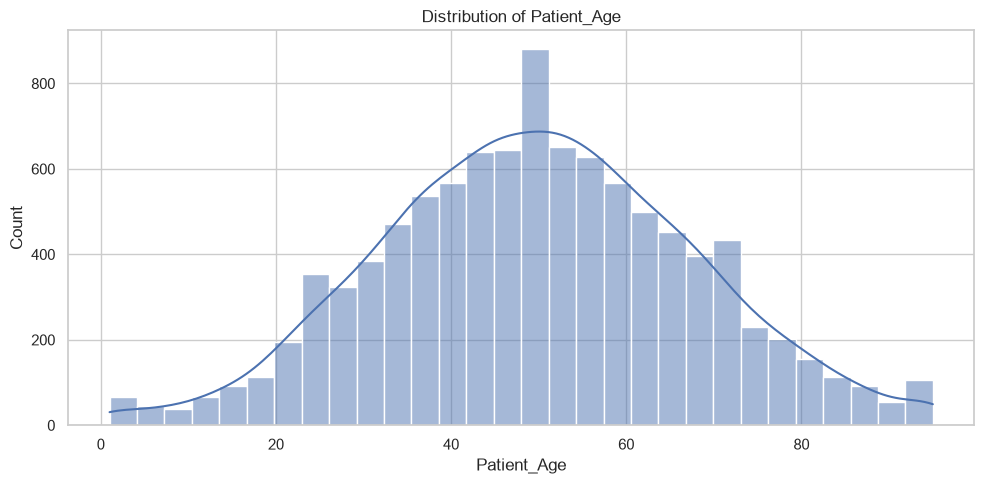

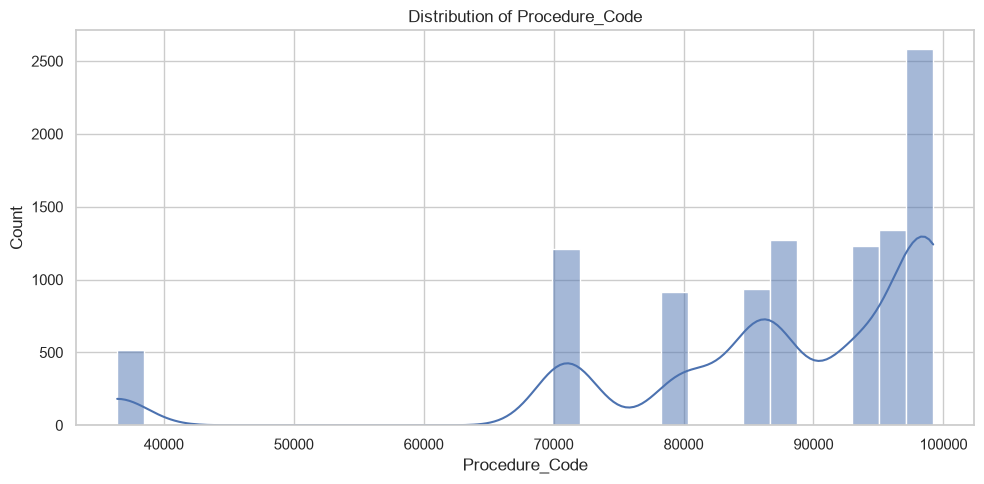

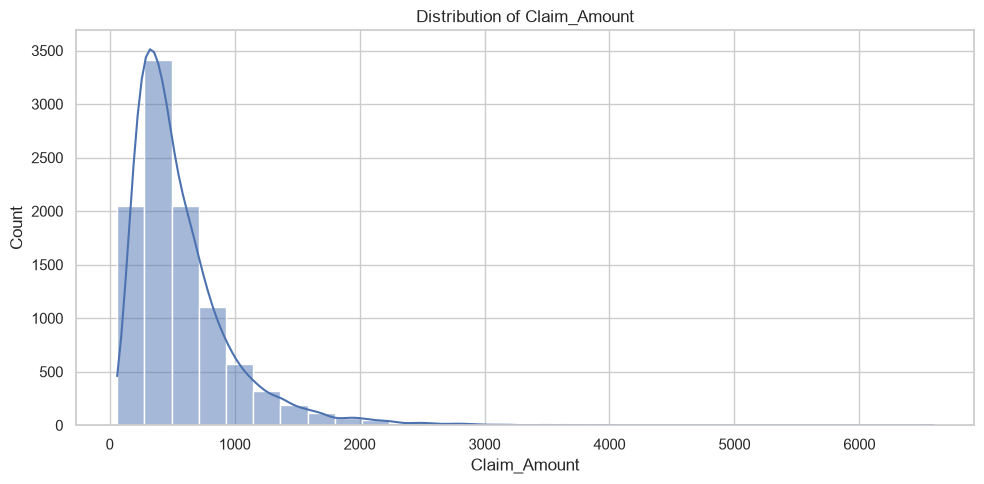

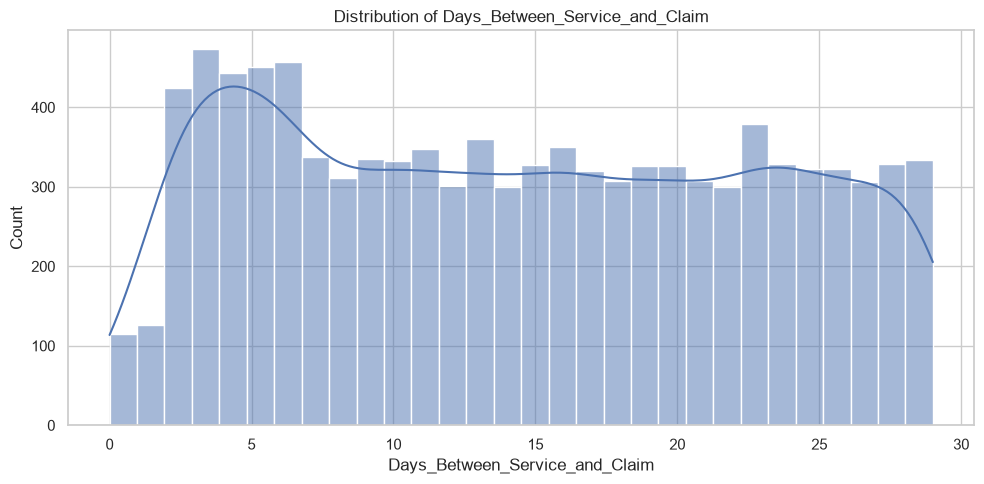

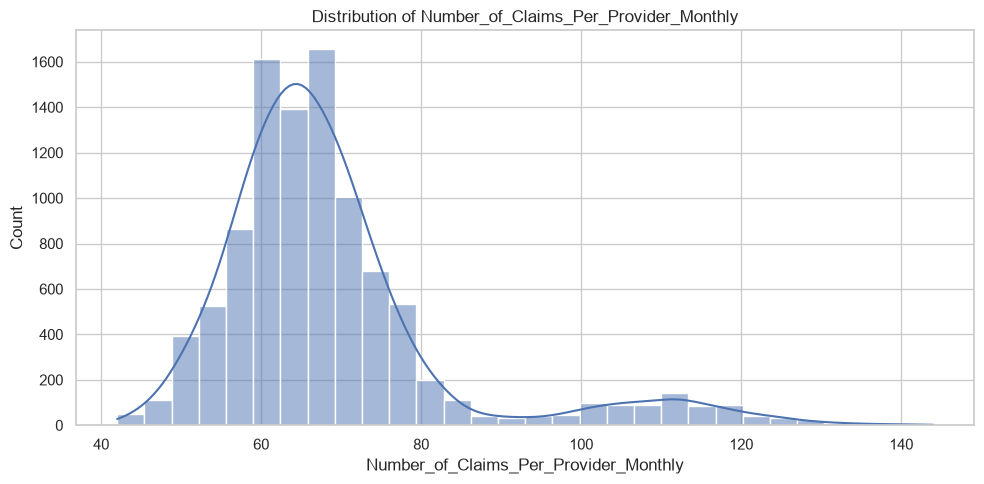

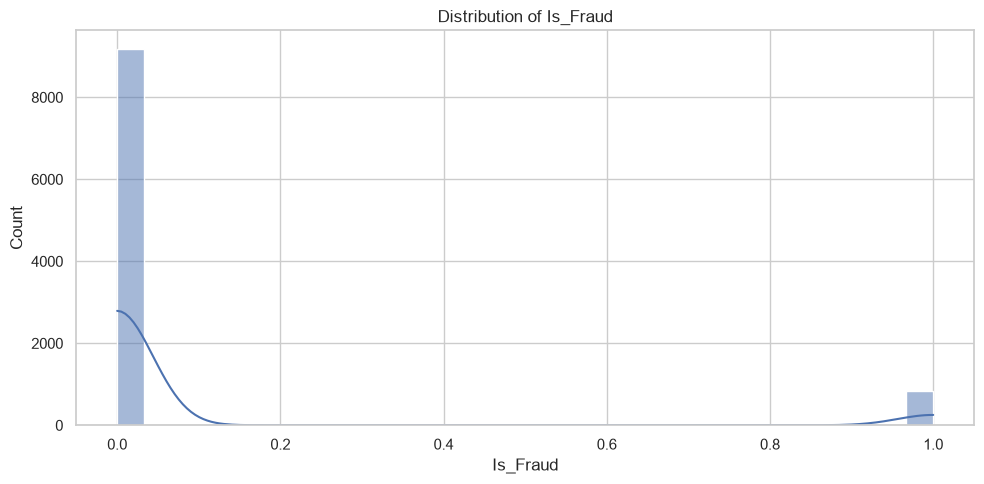

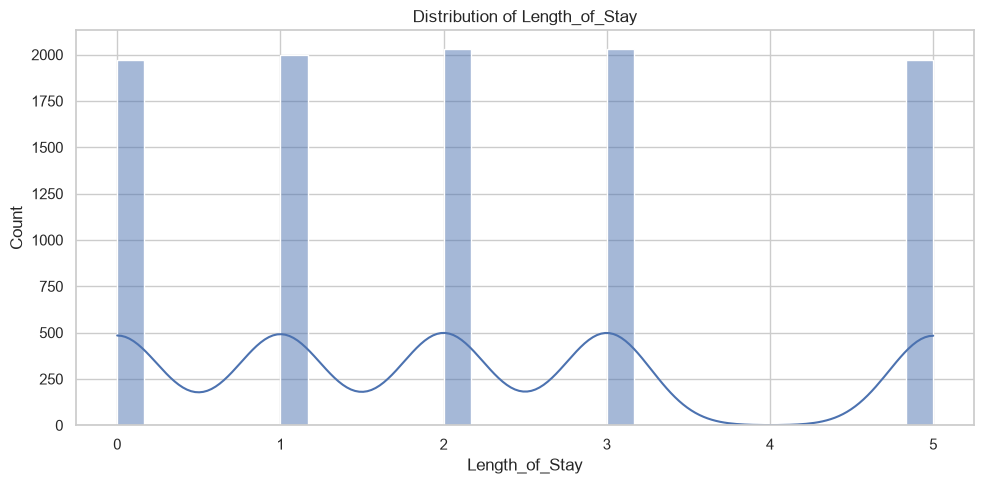

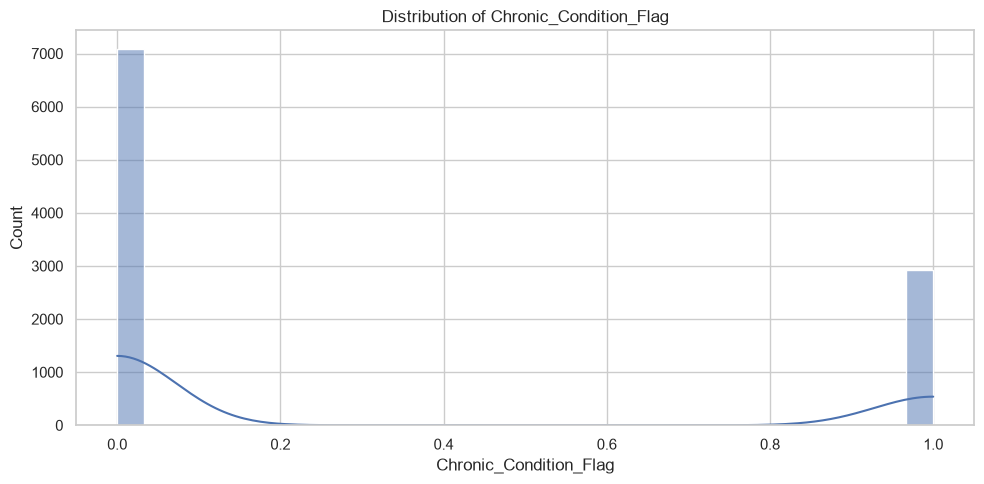

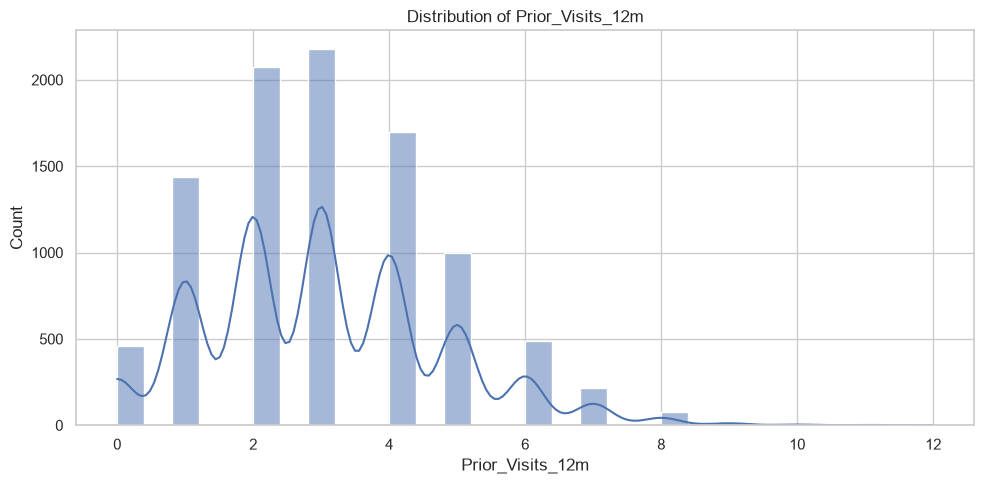

In [36]:
for col in numerical_cols:
    fig, ax = plt.subplots()
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=ax)
    ax.set(title=f"Distribution of {col}")
    fig.tight_layout()
    plt.show()

In [ ]:
# nums = [1, 2, 3, 4]
# mean = sum(nums) / len(nums)

In [ ]:
# mean

2.5

In [ ]:
# nums1 = [1, 2, 3, 4, 100, 200]
# mean = sum(nums1) /len(nums1)

In [41]:
# mean

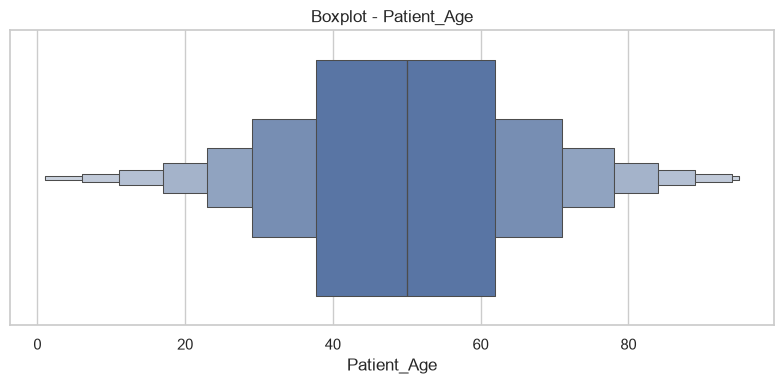

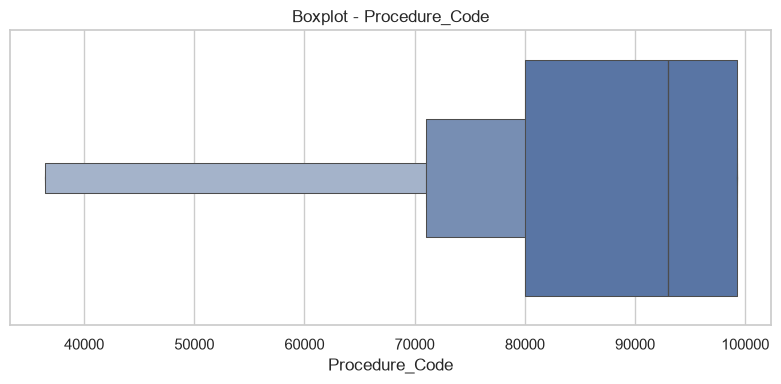

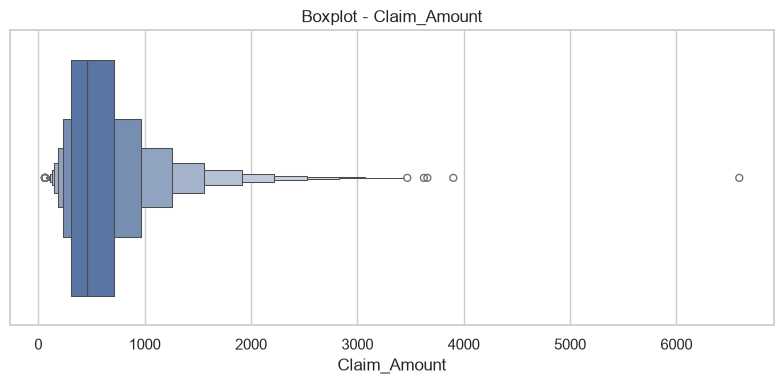

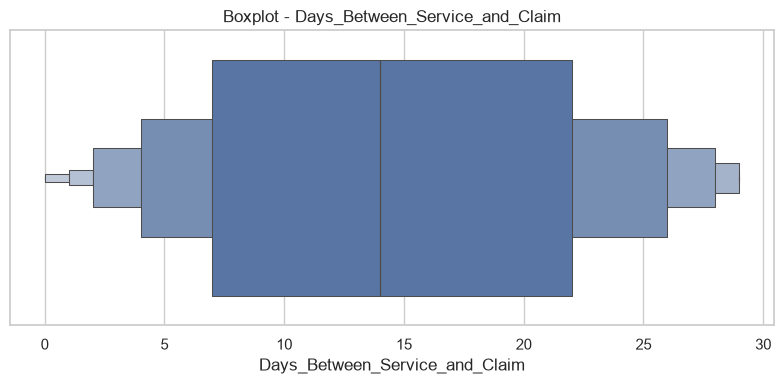

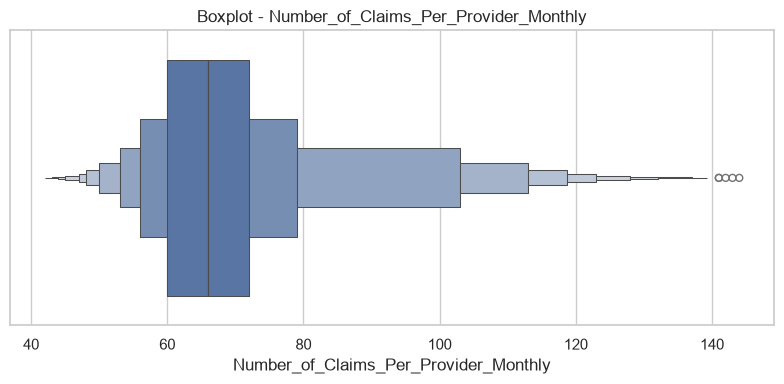

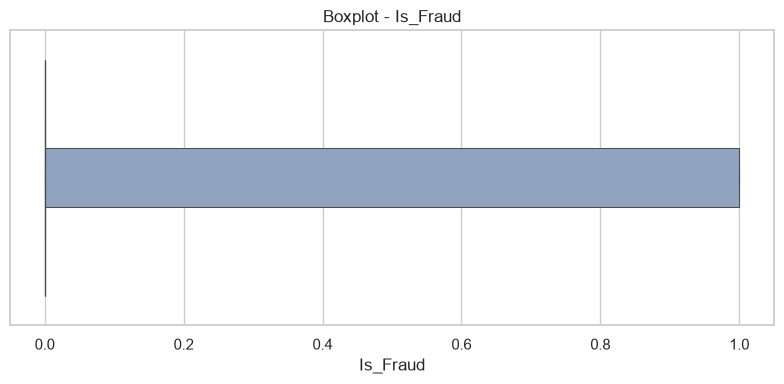

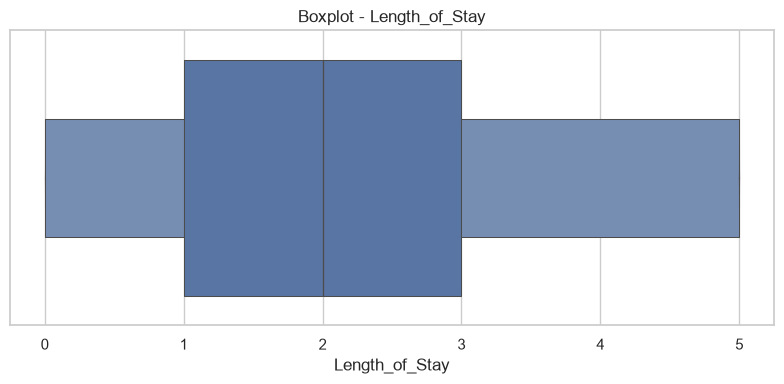

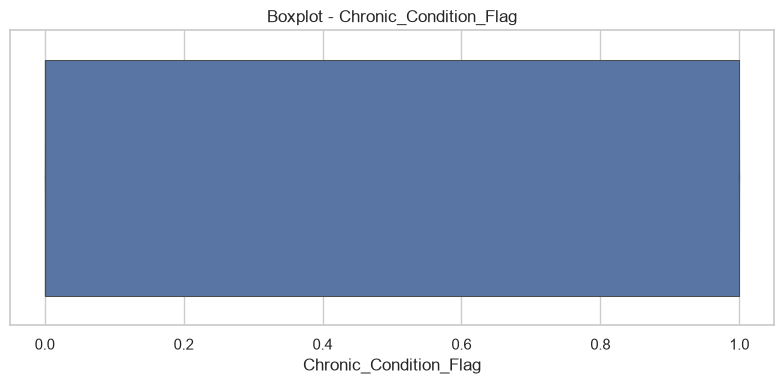

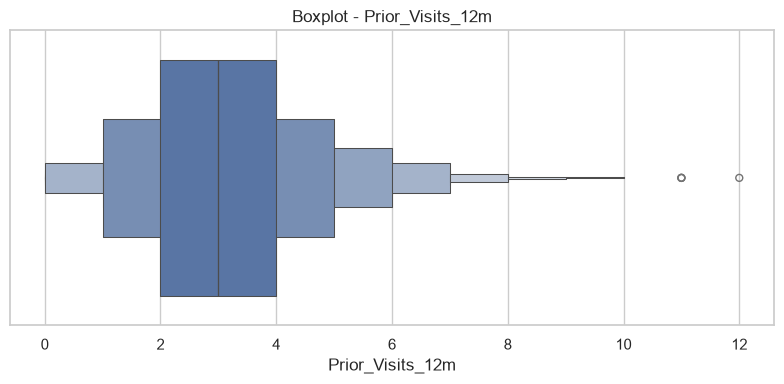

In [42]:
for col in numerical_cols:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxenplot(data=df, x=col, ax=ax)
    ax.set(title=f"Boxplot - {col}")
    fig.tight_layout()
    plt.show()

In [45]:
outliers = []
for col in numerical_cols:
    series = df[col].dropna()
    if series.empty:
        continue
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = int(((series < low) | (series > high)).sum())
    outliers.append({"feature": col, "lower_fence": low, "higher_fence": high, "outlier_count": count, "pct": round(count /len(series * 100), 4)})

display(pd.DataFrame(outliers).sort_values("outlier_count", ascending=False))


,feature,lower_fence,higher_fence,outlier_count,pct
5,Is_Fraud,0.000,0.000,829,0.0829
4,Number_of_Claims_Per_Provider_Monthly,42.000,90.000,817,0.0817
2,Claim_Amount,-304.035,1320.605,552,0.0552
1,Procedure_Code,51313.000,127953.000,515,0.0515
8,Prior_Visits_12m,-1.000,7.000,105,0.0109
0,Patient_Age,1.375,98.375,45,0.0045
3,Days_Between_Service_and_Claim,-15.500,44.500,0,0.0000
6,Length_of_Stay,-2.000,6.000,0,0.0000
7,Chronic_Condition_Flag,-1.500,2.500,0,0.0000


In [46]:
numerical_cols

['Patient_Age',
 'Procedure_Code',
 'Claim_Amount',
 'Days_Between_Service_and_Claim',
 'Number_of_Claims_Per_Provider_Monthly',
 'Is_Fraud',
 'Length_of_Stay',
 'Chronic_Condition_Flag',
 'Prior_Visits_12m']

In [47]:
df['Number_of_Claims_Per_Provider_Monthly']

0        70
1        62
2        60
3        70
4        67
       ... 
9995    115
9996     73
9997     59
9998     55
9999     86
Name: Number_of_Claims_Per_Provider_Monthly, Length: 10000, dtype: int64

In [59]:
out = df[(df['Number_of_Claims_Per_Provider_Monthly'] > 90)]

In [60]:
out

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
7,P0071,C0000007,1,Male,I10,85025,934.34,321.60,,2022-07-13,6,114,,PA,Pending,1,2,Emergency,0,NaN
12,P0293,C0000012,35,Male,I25.10,99213,259.12,208.04,Self-Pay,2022-03-14,26,125,Orthopedics,OH,Approved,0,3,Inpatient,1,1.0
50,P0027,C0000050,26,Female,F41.9,99213,894.71,724.05,Medicare,2024-05-17,4,108,General Practice,FL,Approved,0,5,Inpatient,0,2.0
89,P0133,C0000089,44,Male,J06.9,99214,137.94,131.71,Medicare,2024-11-05,27,102,Orthopedics,OH,Rejected,0,1,Inpatient,1,4.0
92,P0280,C0000092,56,Female,J18.9,93000,293.58,279.26,Medicaid,2021-05-24,15,117,Internal Medicine,GA,Approved,0,0,Emergency,1,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9975,P0259,C0009975,37,Female,K21.9,93000,490.35,373.78,Private,2023-02-14,19,112,General Practice,OH,Approved,0,2,Outpatient,0,3.0
9976,P0002,C0009976,37,Female,I25.10,87086,482.14,373.93,Medicare,2022-04-11,14,119,Orthopedics,PA,Rejected,0,0,Outpatient,1,4.0
9980,P0178,C0009980,61,Male,J06.9,71046,294.65,293.70,Medicaid,2024-08-26,10,116,Neurology,GA,Approved,0,3,Inpatient,0,5.0
9990,P0203,C0009990,59,Female,N39.0,99214,672.26,618.64,Private,2022-01-12,11,92,Neurology,IL,Approved,0,2,Emergency,0,7.0


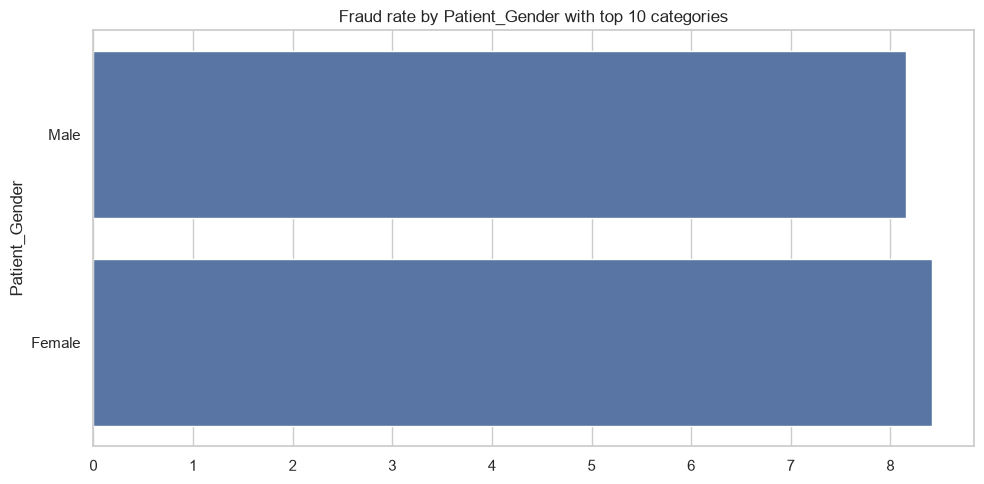

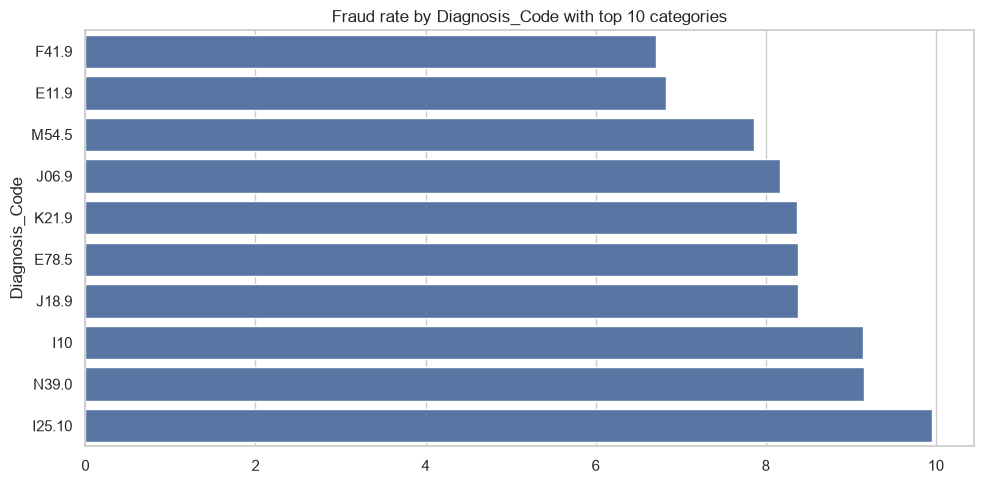

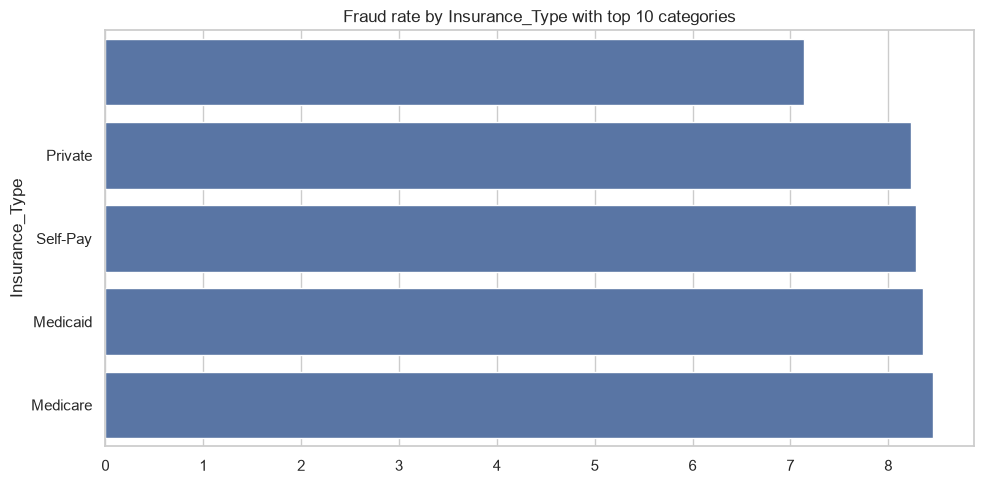

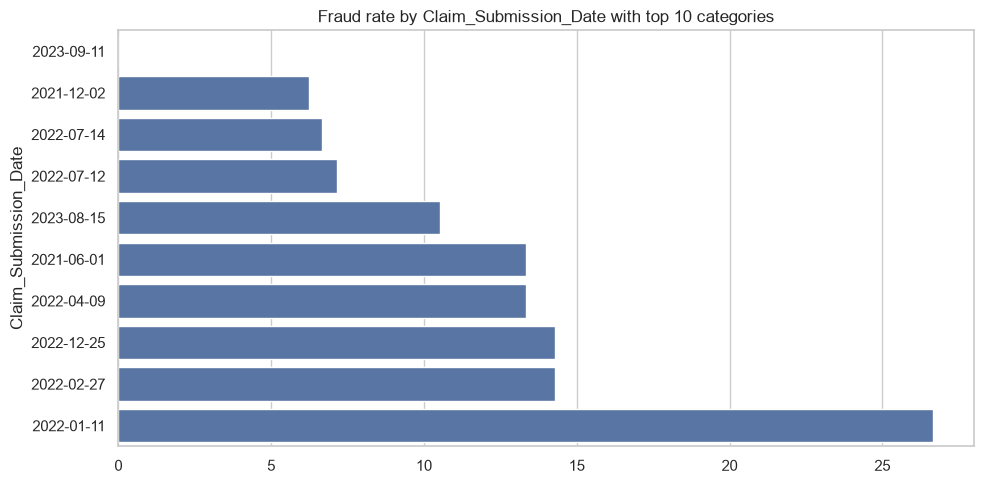

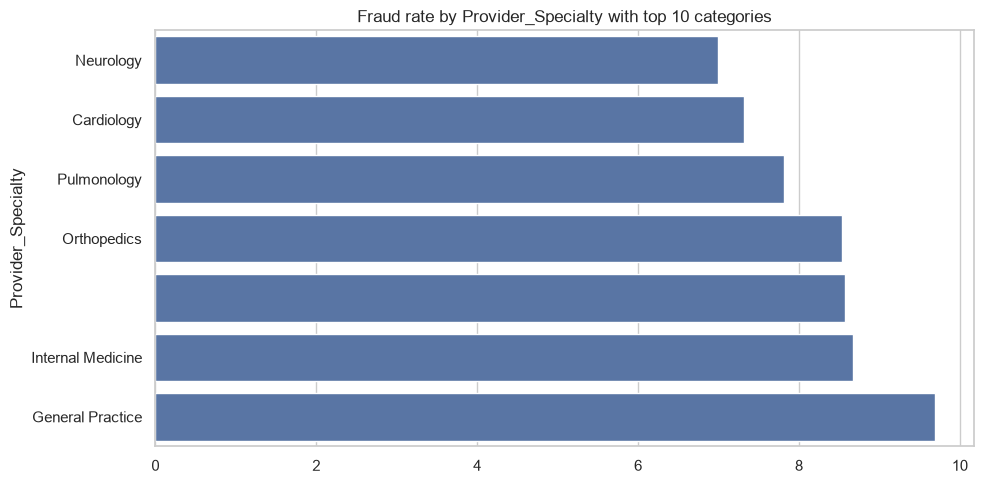

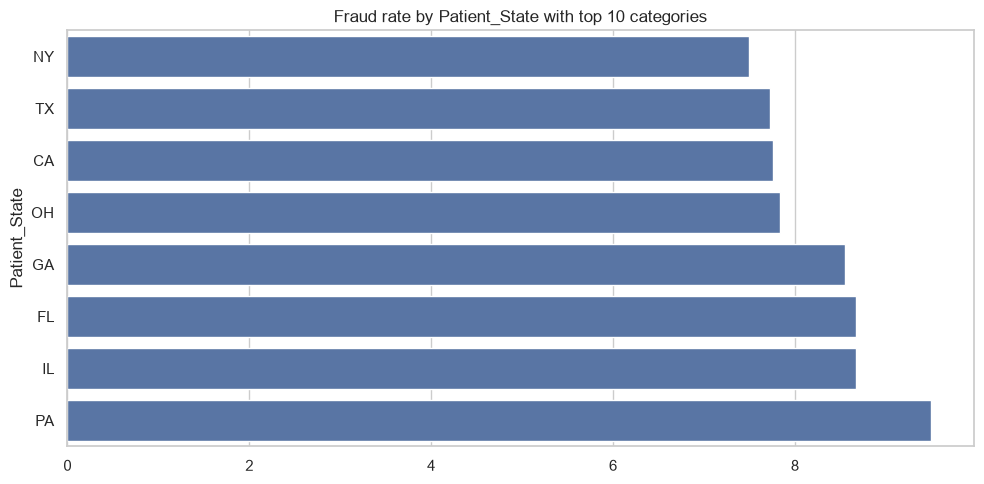

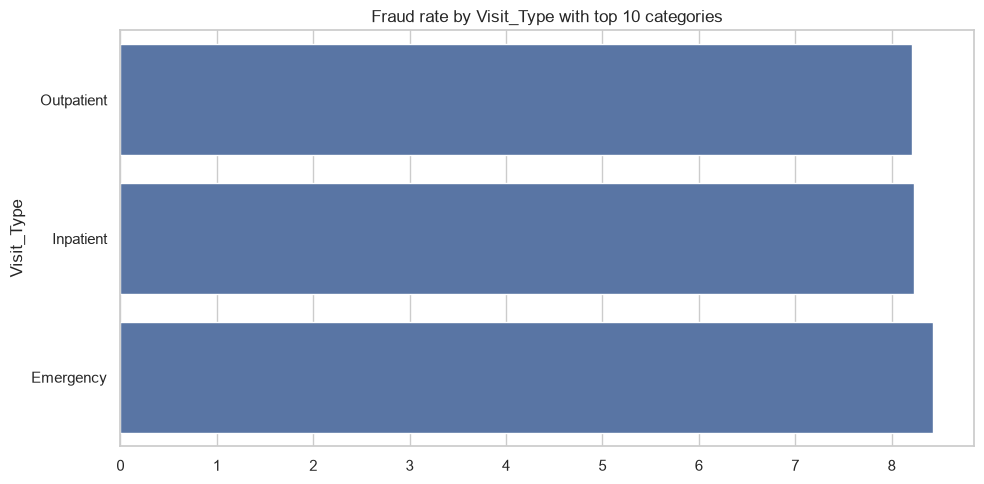

In [ ]:
for col in categorical_cols:
    group = df.groupby(col, dropna=False)["Is_Fraud"].agg(claims="size", fraud_rate="mean")
    top = group.sort_values("claims", ascending=False).head(10).sort_values("fraud_rate")
    labels = top.index.astype(str)
    fig, ax = plt.subplots()
    sns.barplot(x=top["fraud_rate"].to_numpy() * 100, y=labels, ax=ax)
    ax.set(title=f"Fraud rate by {col} with top 10 categories")
    fig.tight_layout()
    plt.show()

In [62]:
categorical_cols

['Patient_Gender',
 'Diagnosis_Code',
 'Insurance_Type',
 'Claim_Submission_Date',
 'Provider_Specialty',
 'Patient_State',
 'Visit_Type']

In [65]:
df.groupby(["Patient_Gender"], dropna=False)["Is_Fraud"].mean()

Patient_Gender
Female    0.084183
Male      0.081616
Name: Is_Fraud, dtype: float64

In [67]:
df.columns

Index(['Provider_ID', 'Claim_ID', 'Patient_Age', 'Patient_Gender',
       'Diagnosis_Code', 'Procedure_Code', 'Claim_Amount', 'Approved_Amount',
       'Insurance_Type', 'Claim_Submission_Date',
       'Days_Between_Service_and_Claim',
       'Number_of_Claims_Per_Provider_Monthly', 'Provider_Specialty',
       'Patient_State', 'Claim_Status', 'Is_Fraud', 'Length_of_Stay',
       'Visit_Type', 'Chronic_Condition_Flag', 'Prior_Visits_12m'],
      dtype='str')

In [71]:
submit_date = df.groupby(["Claim_Submission_Date", ])["Is_Fraud"].mean()

In [74]:
len(df[df["Claim_Submission_Date"] == "2022-01-11"])

15

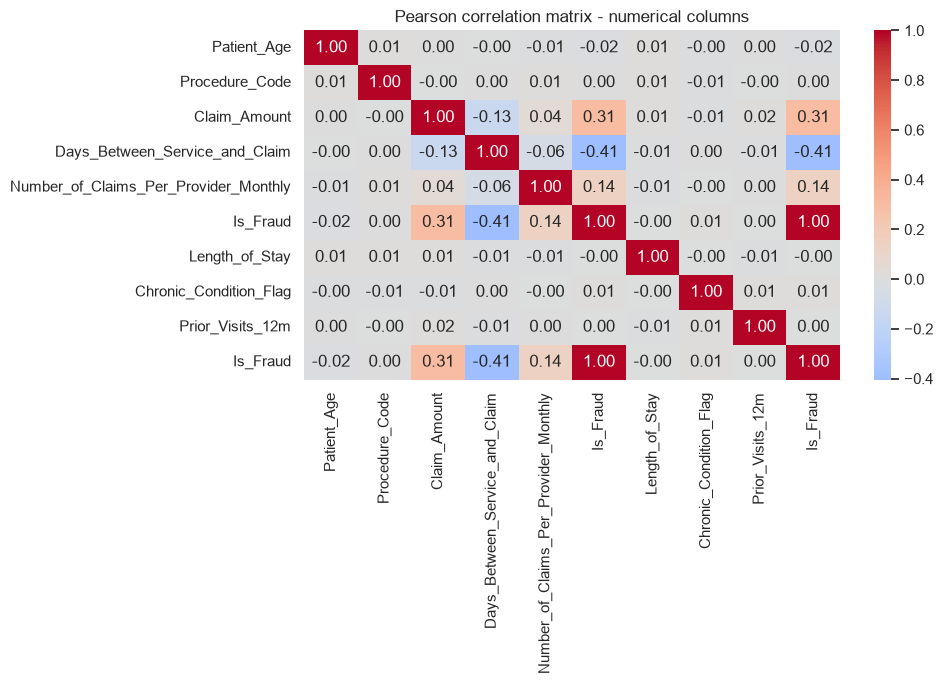

In [77]:
# correlation

corr_cols = numerical_cols + ["Is_Fraud"]
corr = df[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set(title="Pearson correlation matrix - numerical columns")
fig.tight_layout()
plt.show()

,claims,fraud_rate,fraud_count
Month,,,
2024-04-01,190,0.084211,16
2024-05-01,214,0.056075,12
2024-06-01,224,0.058036,13
2024-07-01,209,0.066986,14
2024-08-01,216,0.092593,20
2024-09-01,206,0.121359,25
2024-10-01,194,0.092784,18
2024-11-01,199,0.085427,17
2024-12-01,210,0.061905,13


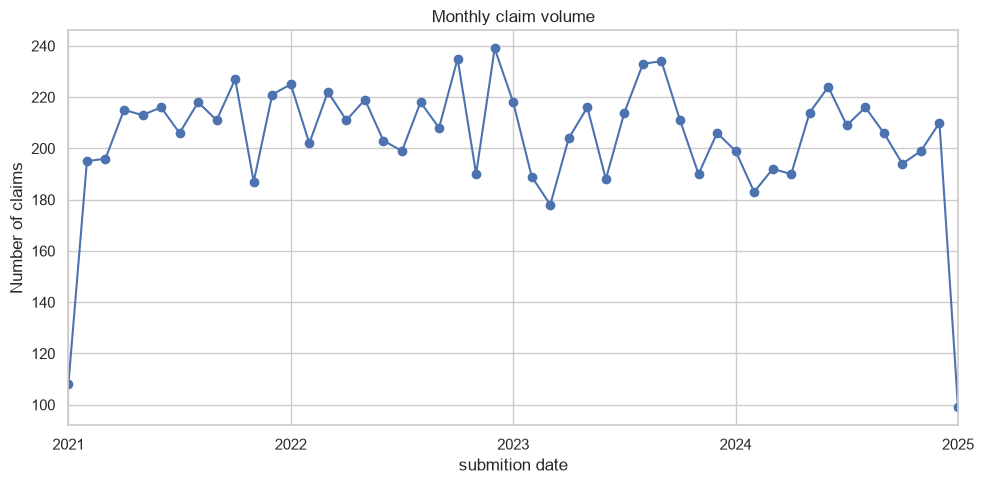

In [84]:
monthly = df.dropna(subset=["Claim_Submission_Date"]).copy()
monthly["Claim_Submission_Date"] = pd.to_datetime(monthly["Claim_Submission_Date"], errors="coerce")
monthly["Month"] = monthly["Claim_Submission_Date"].dt.to_period("M").dt.to_timestamp()
trend = monthly.groupby("Month")["Is_Fraud"].agg(claims="size", fraud_rate="mean", fraud_count="sum")
display(trend.tail(10))

fig, ax = plt.subplots()
trend["claims"].plot(ax=ax, marker="o")
ax.set(title="Monthly claim volume", xlabel="submition date", ylabel="Number of claims")
fig.tight_layout()
plt.show()

In [79]:
monthly

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,P0289,C0009995,79,Male,E78.5,71046,590.19,205.00,Private,2024-09-24,2,115,Internal Medicine,PA,Approved,1,2,Inpatient,1,3.0
9996,P0248,C0009996,66,Male,K21.9,93000,219.73,191.89,Self-Pay,2023-01-04,6,73,Orthopedics,IL,Approved,0,5,Inpatient,0,6.0
9997,P0122,C0009997,43,Female,F41.9,99213,505.24,447.94,Medicare,2024-06-30,6,59,Neurology,OH,Rejected,0,5,Emergency,1,0.0
9998,P0072,C0009998,39,Female,I10,93000,564.25,507.18,Medicare,2022-03-15,8,55,Cardiology,TX,Pending,0,5,Emergency,0,6.0
